# Email Campaign A/B Test

**Primary question:** An online retailer tests two merchandise emails (men's and women's) against no email. Should it send a campaign, which version, and to which customers?

**Data:** [Hillstrom Email Marketing Experiment](https://www.kaggle.com/datasets/sumittarya/hillstrom-email-marketing). 64,000 customers
who purchased in the past year, randomly assigned to a men's email, a women's email, or no email. Visits, purchases, and spend tracked for two weeks after the send.

In [1]:
# Import libraries

import pandas as pd
from scipy.stats import chisquare
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
import matplotlib.pyplot as plt

## Setup

Load the data and confirm its structure. The outcome columns (`visit`, `conversion`, `spend`) are excluded from everything for now so that validation and power analysis are completed blind to results.

In [2]:
# Read in data

df = pd.read_csv("~/Downloads/hillstrom_email_project/hillstrom_email_marketing.csv")
outcomes = ["visit", "conversion", "spend"]

print(df.shape)
print(df.drop(columns=outcomes).head())
print(df.drop(columns=outcomes).dtypes)

(64000, 12)
   recency history_segment  history  mens  womens   zip_code  newbie channel  \
0       10  2) $100 - $200   142.44     1       0  Surburban       0   Phone   
1        6  3) $200 - $350   329.08     1       1      Rural       1     Web   
2        7  2) $100 - $200   180.65     0       1  Surburban       1     Web   
3        9  5) $500 - $750   675.83     1       0      Rural       1     Web   
4        2    1) $0 - $100    45.34     1       0      Urban       0     Web   

         segment  
0  Womens E-Mail  
1      No E-Mail  
2  Womens E-Mail  
3    Mens E-Mail  
4  Womens E-Mail  
recency              int64
history_segment     object
history            float64
mens                 int64
womens               int64
zip_code            object
newbie               int64
channel             object
segment             object
dtype: object


## Experiment Validation

Before trusting any results, confirm that the data is clean and randomized. If the groups differ in size or composition for reasons other than chance, outcome differences can't be attributed to the emails.

### Data Quality

Check for missing values, implausible ranges, and inconsistent category labels.

In [3]:
df["zip_code"] = df["zip_code"].replace("Surburban", "Suburban")
X = df.drop(columns=outcomes)

print("Missing values:\n", X.isna().sum())
print("\nRecency range:", X["recency"].min(), "-", X["recency"].max())
print("History range:", X["history"].min(), "-", X["history"].max())
for col in ["zip_code", "channel", "history_segment", "segment"]:
    print(f"\n{col}:\n", X[col].value_counts())

Missing values:
 recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
dtype: int64

Recency range: 1 - 12
History range: 29.99 - 3345.93

zip_code:
 zip_code
Suburban    28776
Urban       25661
Rural        9563
Name: count, dtype: int64

channel:
 channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

history_segment:
 history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

segment:
 segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


**Result:** No missing values in any column. Recency ranges from 1 to 12 months and prior-year spend from $\$29.99$ to $\$3,345.93$. Both of these values are consistent with a population of customers who purchased in the past year. Prior-year spend is heavily right-skewed (36% of customers spent under $\$100$, about 2% over $\$1,000$), an early sign that the spend outcome will also be skewed. This informs the choice of test later on.

### Sample Ratio Mismatch (SRM)

Customers were meant to be split evenly into thirds. An imbalance larger than chance would explain usually signals a technical problem that can bias results. A chi-square goodness-of-fit test compares observed group sizes to the expected equal split.

In [4]:
counts = X["segment"].value_counts().sort_index()
expected = [len(X) / 3] * 3
stat, p = chisquare(counts, f_exp=expected)
print(counts)
print(f"\nSRM chi-square = {stat:.2f}, p = {p:.4f}")

segment
Mens E-Mail      21307
No E-Mail        21306
Womens E-Mail    21387
Name: count, dtype: int64

SRM chi-square = 0.20, p = 0.9037


**Result:** Group sizes of 21,307 (men's), 21,306 (no email), and 21,387 (women's) give χ² = 0.20, p = 0.90. The largest deviation from a perfect split is about 0.25% (within random variation). No evidence of an imbalance problem.

### Covariate Balance

Equal group sizes don't guarantee the groups contain the same kinds of customers. Each email group is compared to control on every variable recorded before the send.

For numeric and yes/no variables, balance is measured with the standardized mean difference (SMD): the gap between group averages divided by the pooled standard deviation. This puts all variables on one scale, and unlike a p-value it isn't inflated by large sample sizes. An absolute SMD below 0.1 is the standard threshold for balance.

In [5]:
control = X[X["segment"] == "No E-Mail"]
numeric = ["recency", "history", "mens", "womens", "newbie"]

rows = []
for arm in ["Mens E-Mail", "Womens E-Mail"]:
    treat = X[X["segment"] == arm]
    for col in numeric:
        pooled_sd = np.sqrt((treat[col].var() + control[col].var()) / 2)
        smd = (treat[col].mean() - control[col].mean()) / pooled_sd
        rows.append({"arm": arm, "variable": col,
                     "treat_mean": treat[col].mean(),
                     "control_mean": control[col].mean(),
                     "SMD": smd})
print(pd.DataFrame(rows).round(3))

             arm variable  treat_mean  control_mean    SMD
0    Mens E-Mail  recency       5.774         5.750  0.007
1    Mens E-Mail  history     242.836       240.883  0.008
2    Mens E-Mail     mens       0.551         0.553 -0.005
3    Mens E-Mail   womens       0.551         0.548  0.008
4    Mens E-Mail   newbie       0.502         0.502 -0.001
5  Womens E-Mail  recency       5.768         5.750  0.005
6  Womens E-Mail  history     242.537       240.883  0.007
7  Womens E-Mail     mens       0.549         0.553 -0.009
8  Womens E-Mail   womens       0.550         0.548  0.005
9  Womens E-Mail   newbie       0.503         0.502  0.003


**Result:** Every SMD is below 0.01 in absolute value, more than ten times under the 0.1 threshold. In practical terms, average prior-year spend differs by about $\$2$ on a base of about $241, and average recency by about 0.02 months. The share of new customers is essentially identical across groups (about 50% in each).

Note: `mens` and `womens` each average about 0.55, so at least 10% of customers bought from both categories last year. This becomes relevant later in the experiment.

For categorical variables, compare the share of each group in each category and test whether the mix differs more than chance would explain (chi-square test of independence).

In [6]:
for col in ["zip_code", "channel", "history_segment"]:
    table = pd.crosstab(X[col], X["segment"])
    chi2, p, _, _ = chi2_contingency(table)
    print(f"\n{col}: chi-square p = {p:.3f}")
    print(pd.crosstab(X[col], X["segment"], normalize="columns").round(3))


zip_code: chi-square p = 0.579
segment   Mens E-Mail  No E-Mail  Womens E-Mail
zip_code                                       
Rural           0.152      0.147          0.149
Suburban        0.446      0.452          0.451
Urban           0.402      0.401          0.400

channel: chi-square p = 0.458
segment       Mens E-Mail  No E-Mail  Womens E-Mail
channel                                            
Multichannel        0.121      0.122          0.121
Phone               0.434      0.438          0.442
Web                 0.445      0.440          0.437

history_segment: chi-square p = 0.358
segment           Mens E-Mail  No E-Mail  Womens E-Mail
history_segment                                        
1) $0 - $100            0.363      0.357          0.357
2) $100 - $200          0.220      0.227          0.221
3) $200 - $350          0.192      0.190          0.194
4) $350 - $500          0.098      0.100          0.102
5) $500 - $750          0.075      0.078          0.078
6) $75

**Result:** Category shares for location, channel, and spending tier differ by about one percentage point or less across groups, and none of the chi-square tests are significant (p = 0.36 to 0.58).

**Validation conclusion:** The groups are comparable in both size and composition. Randomization worked as intended, so differences in outcomes can be attributed to the emails.

## Power Analysis

A power analysis shows how large an effect the test could reliably detect. If the test can only detect large effects, a non-significant result means "no large effect," not "no effect."

Estimating power requires a baseline rate (the conversion and visit rates without an email). Computing it from the control group would mean
viewing outcomes, so a range of plausible baselines is used instead, keeping the analysis blind.

Settings: α = 0.025 (Bonferroni-adjusted for two comparisons), power = 80%, about 21,300 customers per group.

In [7]:
n = 21_300         
alpha = 0.025       
power = 0.80
z_total = norm.ppf(1 - alpha / 2) + norm.ppf(power)

rows = []
for metric, baselines in {"conversion": [0.005, 0.01, 0.02],
                          "visit": [0.10, 0.15, 0.20]}.items():
    for p in baselines:
        mde = z_total * np.sqrt(2 * p * (1 - p) / n)
        rows.append({"metric": metric, "baseline": p,
                     "MDE_abs_pts": mde * 100,
                     "MDE_relative_%": mde / p * 100})
print(pd.DataFrame(rows).round(4))

       metric  baseline  MDE_abs_pts  MDE_relative_%
0  conversion     0.005       0.2107         42.1433
1  conversion     0.010       0.2972         29.7249
2  conversion     0.020       0.4182         20.9122
3       visit     0.100       0.8962          8.9624
4       visit     0.150       1.0667          7.1116
5       visit     0.200       1.1950          5.9749


**Result:** The two metrics differ sharply in sensitivity.

- **Visit** is well-powered: the test can detect absolute lifts of about 0.9 to 1.2
  percentage points, or relative lifts of about 6 to 9%.
- **Conversion** is not: because purchases are rare, the test can only reliably detect
  absolute lifts of about 0.2 to 0.4 points, which at baselines of 0.5 to 2% means relative
  lifts of about 20 to 40%.

A non-significant conversion result would not show that an email has no effect, only that any effect is smaller than the test can detect. Results are interpreted with this in mind.

## Primary Results

### Conversion and Visit

Each email is compared to the no-email control with a two-proportion z-test. With two primary comparisons, the significance threshold is Bonferroni-adjusted to α = 0.025.

In [8]:
control = df[df["segment"] == "No E-Mail"]
alpha = 0.025

rows = []
for arm in ["Mens E-Mail", "Womens E-Mail"]:
    treat = df[df["segment"] == arm]
    for metric in ["conversion", "visit"]:
        counts = [treat[metric].sum(), control[metric].sum()]
        nobs = [len(treat), len(control)]
        z, p = proportions_ztest(counts, nobs)
        low, high = confint_proportions_2indep(counts[0], nobs[0], counts[1], nobs[1],
                                               method="wald", alpha=alpha)
        rows.append({"arm": arm, "metric": metric,
                     "treat_%": counts[0] / nobs[0] * 100,
                     "control_%": counts[1] / nobs[1] * 100,
                     "diff_pts": (counts[0] / nobs[0] - counts[1] / nobs[1]) * 100,
                     "CI_low": low * 100, "CI_high": high * 100,
                     "p_value": p, "significant": p < alpha})
pd.set_option("display.width", 200)
print(pd.DataFrame(rows).round(4))

             arm      metric  treat_%  control_%  diff_pts  CI_low  CI_high  p_value  significant
0    Mens E-Mail  conversion   1.2531     0.5726    0.6805  0.4741   0.8869   0.0000         True
1    Mens E-Mail       visit  18.2757    10.6167    7.6590  6.9001   8.4179   0.0000         True
2  Womens E-Mail  conversion   0.8837     0.5726    0.3111  0.1267   0.4955   0.0002         True
3  Womens E-Mail       visit  15.1400    10.6167    4.5233  3.7984   5.2483   0.0000         True


**Result:** Both emails significantly increased both metrics.

| | Control | Men's email | Women's email |
|---|---|---|---|
| **Conversion** | 0.57% | 1.25% (+0.68 pts, +119%) | 0.88% (+0.31 pts, +54%) |
| 97.5% CI on lift | | +0.47 to +0.89 pts | +0.13 to +0.50 pts |
| p-value | | < 0.0001 | 0.0002 |
| **Visit** | 10.62% | 18.28% (+7.66 pts, +72%) | 15.14% (+4.52 pts, +43%) |
| 97.5% CI on lift | | +6.90 to +8.42 pts | +3.80 to +5.25 pts |
| p-value | | < 0.0001 | < 0.0001 |

**Connection to power analysis:** observed control conversion was 0.57%, where the minimum detectable effect is about 0.23 points. Both conversion lifts exceed this, so the test was adequately powered to detect them.

In business terms, per 1,000 customers emailed, the men's email generated about 7 additional purchasers and the women's email about 3.

### Spend

Spend is the revenue outcome. Because most customers buy nothing, its distribution is expected to be extremely skewed, which violates the assumptions of a t-test. Instead, a bootstrap is used: each group is resampled with replacement 10,000 times, the difference in mean spend is recomputed each time, and the middle 97.5% of those differences forms the confidence interval. No assumptions about the shape of the distribution are needed.

In [9]:
print("Share of customers with $0 spend:", round((df["spend"] == 0).mean() * 100, 2), "%")
print("\nSpend among buyers:\n", df.loc[df["spend"] > 0, "spend"].describe().round(2))

rng = np.random.default_rng(42)
n_boot = 10_000
c_spend = control["spend"].to_numpy()

rows = []
for arm in ["Mens E-Mail", "Womens E-Mail"]:
    t_spend = df.loc[df["segment"] == arm, "spend"].to_numpy()
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = (rng.choice(t_spend, len(t_spend)).mean()
                    - rng.choice(c_spend, len(c_spend)).mean())
    low, high = np.percentile(diffs, [1.25, 98.75])   # 97.5% CI
    rows.append({"arm": arm,
                 "treat_mean_$": t_spend.mean(), "control_mean_$": c_spend.mean(),
                 "diff_$": t_spend.mean() - c_spend.mean(),
                 "CI_low": low, "CI_high": high,
                 "per_1000_customers_$": (t_spend.mean() - c_spend.mean()) * 1000})
print(pd.DataFrame(rows).round(3))

Share of customers with $0 spend: 99.1 %

Spend among buyers:
 count    578.00
mean     116.36
std      107.87
min       29.99
25%       32.27
50%       80.80
75%      153.35
max      499.00
Name: spend, dtype: float64
             arm  treat_mean_$  control_mean_$  diff_$  CI_low  CI_high  per_1000_customers_$
0    Mens E-Mail         1.423           0.653   0.770   0.441    1.097               769.827
1  Womens E-Mail         1.077           0.653   0.424   0.134    0.716               424.412


**Distribution:** 99.1% of customers spent $\$0$. Among the 578 buyers, the median order was
$\$80.80$ and the mean $\$116.36$. The maximum is exactly $\$499.00$, which may indicate that spend
is capped in this dataset; if so, effects on spend would be slightly understated.

**Result:** Both emails significantly increased average spend per customer.

| | Control | Men's email | Women's email |
|---|---|---|---|
| Mean spend per customer | $\$0.65$ | $\$1.42$ | $\$1.08$ |
| Lift | | +$\$0.77$ (+118%) | +$\$0.42$ (+65%) |
| 97.5% CI on lift | | +$\$0.44$ to +$\$1.10$ | +$\$0.13$ to +$\$0.72$ |
| Lift per 1,000 customers emailed | | ≈ $\$770$ | ≈ $\$424$ |

**Interpretation:** Each conversion lift multiplied by the average order value (about $\$116$) closely matches the observed spend lift ($\$0.79$ vs. $\$0.77$ for men's; $\$0.36$ vs. $\$0.42$ for women's). This suggests the revenue gain comes mainly from more customers buying, rather than customers buying larger orders.

## Segment Analysis (Exploratory)

The primary results show that both emails work on average. This section asks, for who?

Each email's lift over control is estimated within segments defined by prior purchase category (men's only, women's only, or both), new vs. existing customer, purchase channel, and location, with 95% confidence intervals. Visit is the main metric for this section, since segments are smaller groups and conversion was already the less sensitive metric at full sample size.

In [10]:
df["buyer_type"] = np.select(
    [(df["mens"] == 1) & (df["womens"] == 1), df["mens"] == 1, df["womens"] == 1],
    ["Both", "Mens only", "Womens only"], default="Neither")

def segment_lifts(seg_col, metric):
    rows = []
    for level in sorted(df[seg_col].unique()):
        sub = df[df[seg_col] == level]
        c = sub[sub["segment"] == "No E-Mail"]
        for arm in ["Mens E-Mail", "Womens E-Mail"]:
            t = sub[sub["segment"] == arm]
            low, high = confint_proportions_2indep(t[metric].sum(), len(t), c[metric].sum(), len(c),
                                                   method="wald", alpha=0.05)
            rows.append({seg_col: level, "arm": arm, "n_treat": len(t),
                         "treat_%": t[metric].mean() * 100, "control_%": c[metric].mean() * 100,
                         "lift_pts": (t[metric].mean() - c[metric].mean()) * 100,
                         "CI_low": low * 100, "CI_high": high * 100})
    return pd.DataFrame(rows).round(2)

for metric in ["visit", "conversion"]:
    for col in ["buyer_type", "newbie", "channel", "zip_code"]:
        print(f"\n=== {metric} by {col} ===")
        print(segment_lifts(col, metric))


=== visit by buyer_type ===
    buyer_type            arm  n_treat  treat_%  control_%  lift_pts  CI_low  CI_high
0         Both    Mens E-Mail     2181    31.50      18.05     13.44   10.91    15.98
1         Both  Womens E-Mail     2118    25.17      18.05      7.11    4.65     9.57
2    Mens only    Mens E-Mail     9558    16.90       9.98      6.92    5.96     7.88
3    Mens only  Womens E-Mail     9622    11.09       9.98      1.11    0.24     1.97
4  Womens only    Mens E-Mail     9568    16.64       9.58      7.06    6.11     8.01
5  Womens only  Womens E-Mail     9647    16.98       9.58      7.40    6.44     8.35

=== visit by newbie ===
   newbie            arm  n_treat  treat_%  control_%  lift_pts  CI_low  CI_high
0       0    Mens E-Mail    10621    21.16      13.37      7.78    6.77     8.79
1       0  Womens E-Mail    10624    17.39      13.37      4.01    3.04     4.98
2       1    Mens E-Mail    10686    15.41       7.88      7.53    6.68     8.38
3       1  Womens E-

**Main finding: the emails behave differently by prior purchase category.**

| Buyer type | Men's email visit lift | Women's email visit lift | Men's email conversion lift | Women's email conversion lift |
|---|---|---|---|---|
| Men's only | +6.9 pts | +1.1 pts | +0.60 pts | +0.06 pts (CI includes 0) |
| Women's only | +7.1 pts | +7.4 pts | +0.57 pts | +0.51 pts |
| Both | +13.4 pts | +7.1 pts | +1.50 pts | +0.53 pts (CI includes 0) |

- **The women's email works mainly on customers who already buy women's merchandise.**
  Among men's-only buyers, its visit lift was small and its conversion lift was not distinguishable from zero.
- **The men's email works across all buyer types**, with nearly identical lifts for men's-only and women's-only buyers.
- **Among women's-only buyers, the two emails perform about the same.** The women's email's weaker overall result is driven almost entirely    by men's-only buyers.
- **Customers who bought both categories respond most strongly**, making them the most valuable audience to email.

**Interpreting the null result with power in mind:** with about 9,600 customers per group in the men's-only segment, the test could only reliably detect conversion lifts of roughly 0.3 points or more. So the +0.06 result rules out a large effect, not any effect. The visit
result, which is more sensitive, shows a small but real lift. The accurate conclusion is that the women's email has *little* effect on men's-only buyers, not *no* effect.

**Smaller patterns, held loosely:** the women's email showed no clear conversion lift among existing customers, phone customers, or rural customers. These appear in a single metric only, and with 32 intervals computed, one or two surprising results are expected by chance.
The buyer-type pattern is more credible because it is large, appears in both visit and conversion, and has a plausible explanation (customers respond to relevant merchandise).

**Simpson's paradox check:** Simpson's paradox occurs when an overall effect reverses within subgroups. No reversal was found: every segment shows a positive lift for both emails, matching the overall direction.

### Visual summary

**Figure 1:** Visit lift by prior purchase category, with 95% confidence intervals. The
women's email barely moves men's-only buyers, while the men's email lifts all groups.

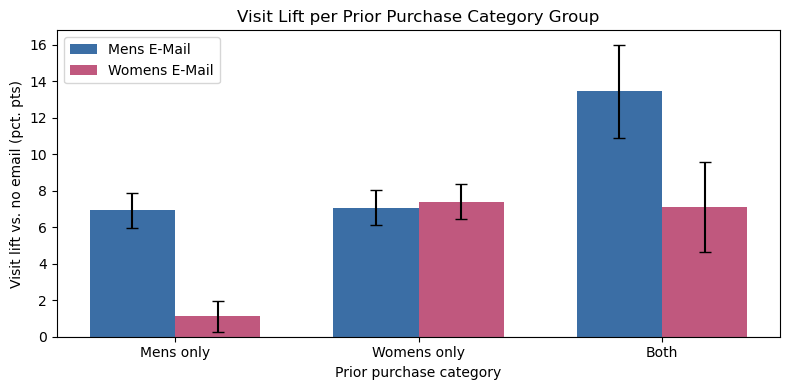

In [13]:
seg = segment_lifts("buyer_type", "visit")
types = ["Mens only", "Womens only", "Both"]
x = np.arange(len(types))

fig, ax = plt.subplots(figsize=(8, 4))
for i, (arm, color) in enumerate([("Mens E-Mail", "#3b6ea5"), ("Womens E-Mail", "#c0587e")]):
    d = seg[seg["arm"] == arm].set_index("buyer_type").loc[types]
    err = [d["lift_pts"] - d["CI_low"], d["CI_high"] - d["lift_pts"]]
    ax.bar(x + (i - 0.5) * 0.35, d["lift_pts"], width=0.35, yerr=err,
           capsize=4, label=arm, color=color)
ax.set_xticks(x); ax.set_xticklabels(types)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Prior purchase category")
ax.set_ylabel("Visit lift vs. no email (pct. pts)")
ax.set_title("Visit Lift per Prior Purchase Category Group")
ax.legend()
plt.tight_layout()
plt.savefig("visit_lift_by_buyer_type.png", dpi=150)
plt.show()

## Recommendation

**Decision: Send the men's email as the default campaign.**

**Evidence:**
- Both emails significantly increased purchases, visits, and revenue vs. no email.
- The men's email showed the larger lift vs. control: conversion rose from 0.57% to 1.25%
  (about 7 additional buyers per 1,000 emailed) and revenue by about $\$0.77$ per customer
  (about $\$770$ per 1,000 emailed). The women's email raised conversion to 0.88% (about 3
  additional buyers per 1,000) and revenue by about $\$0.42$ per customer.
- The men's email was effective for every customer type, while the women's email worked
  mainly for customers who already buy women's merchandise. Among women's-only buyers,
  the two performed about the same, so the men's email gives up little even with the
  women's email's best audience.
- The results rest on a validated experiment: balanced groups, no sample ratio mismatch,
  and adequate power for the observed effects.

**Caveats:**
- **No direct comparison.** Each email was compared to control, not to each other, so the
  men's email's larger lift is suggestive rather than tested. A direct comparison should
  be confirmed before treating it as definitive.
- **These are two specific emails.** The results compare these particular campaigns, not
  men's vs. women's content in general. A different women's email could perform differently.
- **Segment findings are exploratory** and should be confirmed before being used for targeting.

**Recommended next test:** Compare three strategies directly, tracking unsubscribes as a guardrail:
1. Men's email to everyone
2. Both emails to everyone
3. Targeted: each customer receives the email matching their purchase history, which the segment analysis suggests could match option 1's performance while still promoting women's merchandise to the customers who respond to it